# How the junction region is found

An assembloid is two organoids fused together. One of them carries the labelled cells (GFP, the 488 channel); the other does not. What we measure is what crossed from the first into the second, so we need a **region just across the junction**, on the organoid the cells migrate *into*.

This notebook walks through how the viewer finds that region by itself, one step at a time, on a real section whose junction was also **drawn by hand**: `2025_09_26_Asssembloid_034-033_s13`. The hand-drawn line is drawn on the figures as a **cyan dashed line**, and the distance between it and the automatic line is printed where the line changes. Every step calls the same function the viewer calls (`microscopy_viewer/junction.py`), so what you see here is what a batch run does.

At the end, the same steps on a section of the same slide where the finder **fails** (`..._s17`): it reports *ok*, but its line is about 340 µm from the hand-drawn one. That section shows why.

**The idea in one paragraph.** The label channels tell us *which side is which*, but not where the two organoids meet: labelled cells are patchy, and a threshold on them draws a line round the brightest patch instead of round the organoid. The DAPI channel tells us *where they meet*: there is a thin dark line between two fused organoids. So the labels are used only to plant one seed in each organoid (GFP (488) for the first, the other organoid's own label, the 555 channel, for the second) and the tissue is then cut between the two seeds along the cheapest path, where cutting through a dark DAPI line is cheap.

| Step | What | Function |
|---|---|---|
| 0 | Shrink the scan to an overview at ~5 µm per pixel | `build_overview` |
| 1 | Find the tissue: wherever any channel stands above the slide | `tissue_mask` |
| 2 | Map where the labelled cells are | `cell_density` |
| 3 | Plant one seed in each organoid: the dense core of each organoid's own label | `find_seeds` |
| 4 | Price every pixel: cheap along a dark DAPI line | `line_cost` |
| 5 | Cut the tissue between the seeds (minimum cut) | `split_tissue` |
| 5b | Cut again, paying for every turn: no corners round a crack | `straighten_cut` |
| 6 | Turn the cut into a smooth junction line | `trace_interface` |
| 7 | Build the band beside the line, inside one organoid, a rim past its edge | `_build_band` |
| 8 | Put the band on the full-resolution pixel grid | `full_resolution_band` |
| 9 | Score the sample: ok, check or fail | `quality_flags` |
| + | A line drawn by hand gets the same kind of band | `band_along_tissue` |
| ! | A section where it fails, and why | |

For the pixel-level detail of each step (which pixels a filter looks at, what number each ends up with) see [junction_pixels.ipynb](junction_pixels.ipynb), which runs on the same two sections.

**What it needs.** The scans on `D:\Slidescanner extracted\` and the overviews and hand-drawn lines cached by the evaluation (`junction_eval\overviews\`, made by `notebooks/validation/junction_tuning.py`). It only reads. No GPU; reading the scan takes about a minute.

**Run the cells in order, from the top** (*Run All*). Each step uses what the steps before it made, so a cell run on its own, or after a cell above it failed, stops with `NameError: name ... is not defined`. If that happens: *Restart* the kernel and *Run All*.

In [1]:
from pathlib import Path
import ssl
import sys

# Some Python installations on Windows cannot read the Windows certificate store
# ("SSLError: [ASN1: NOT_ENOUGH_DATA]"). Nothing here uses the network, but reading
# an image goes through dask, which imports a library that builds an SSL context
# on import and so fails for that reason. Where that is the case, skip the store.
try:
    ssl.create_default_context()
except ssl.SSLError:
    ssl.SSLContext._load_windows_store_certs = lambda self, storename, purpose: None

import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage

# The repository root, wherever the notebook is run from.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "microscopy_viewer").is_dir())
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "notebooks" / "validation"))

from microscopy_viewer import fusion as fu
from microscopy_viewer import junction as jn
from microscopy_viewer import loaders
import junction_tuning as jt          # the hand-drawn lines and cached overviews of the evaluation

DATA = Path(r"D:\Slidescanner extracted")
WORKED = "2025_09_26_Asssembloid_034-033_s13"     # the section walked through
FAILED = "2025_09_26_Asssembloid_034-033_s17"     # the section where it fails, at the end
SAMPLE = DATA / f"{WORKED}.ome.tiff"

# The hand-drawn junction, and the band settings it was drawn with (300 µm wide, 2 µm off the line).
cached, manual_band, manual_line_um, base = jt.load_case(WORKED)
options = jn.JunctionOptions(width_um=base["width_um"], gap_um=base["gap_um"], save=False)

plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 11, "image.interpolation": "nearest"})
HAND = dict(color="cyan", ls="--", lw=1.8)          # the hand-drawn line, in every figure


def show(ax, image, title, cmap="gray", **kwargs):
    ax.imshow(image, cmap=cmap, **kwargs)
    ax.set_title(title)
    ax.set_axis_off()


def stretch(plane, low=1.0, high=99.8):
    # Scale a plane to 0-1 between two percentiles, for display only.
    a, b = np.percentile(plane[plane > 0], (low, high))
    return np.clip((plane - a) / max(b - a, 1e-6), 0, 1)


def hand(ax, line_um, um, offset=(0, 0), **style):
    """A hand-drawn line (µm) on overview pixels, shifted by *offset* for a zoomed panel."""
    ax.plot(line_um[:, 1] / um - offset[1], line_um[:, 0] / um - offset[0], **{**HAND, **style})


def off_by(line_um, filled, um, manual=None):
    """Mean distance (µm) between *line_um* and the hand-drawn line, over the tissue."""
    manual = manual_line_um if manual is None else manual
    region = ndimage.binary_dilation(filled, iterations=max(1, int(np.ceil(base["margin_um"] / um))))
    return jt.line_distance(manual, line_um, region, um)[0]


specs = loaders.load_path(SAMPLE)
for spec in specs:
    print(f"{spec.channel_name:8s} shape {tuple(spec.data.shape)}  pixel {tuple(round(float(v), 3) for v in spec.scale)} µm")

AF555    shape (3, 7584, 7567)  pixel (3.0, 0.325, 0.325) µm
AF488    shape (3, 7584, 7567)  pixel (3.0, 0.325, 0.325) µm
AF405    shape (3, 7584, 7567)  pixel (3.0, 0.325, 0.325) µm


## Step 0 — the overview

A slide scan is tens of megapixels and a gigabyte on disk. An organoid is millimetres across, and nothing about *where its junction is* lives below a few micrometres. So every channel is flattened over Z (maximum) and shrunk to about **5 µm per pixel**. Everything up to step 7 happens on this small image, which is why the whole thing takes seconds.

Two details:

- Shrinking keeps every *n*-th pixel instead of averaging blocks. A labelled cell is a few pixels wide at full resolution; averaging would dissolve it into the background we want to tell it apart from.
- For DAPI a second, block-*averaged* copy is kept as well (`nuclear_mean`). The dark line between organoids is faint, and averaging is what makes a faint continuous line stand out from pixel noise. That copy is used in step 4.

full resolution : 7567 x 7584 px at 0.325 µm
overview        : 505 x 506 px at 4.88 µm  (every 15th pixel)
nuclear channel : AF405    labelled-cell channel : AF488


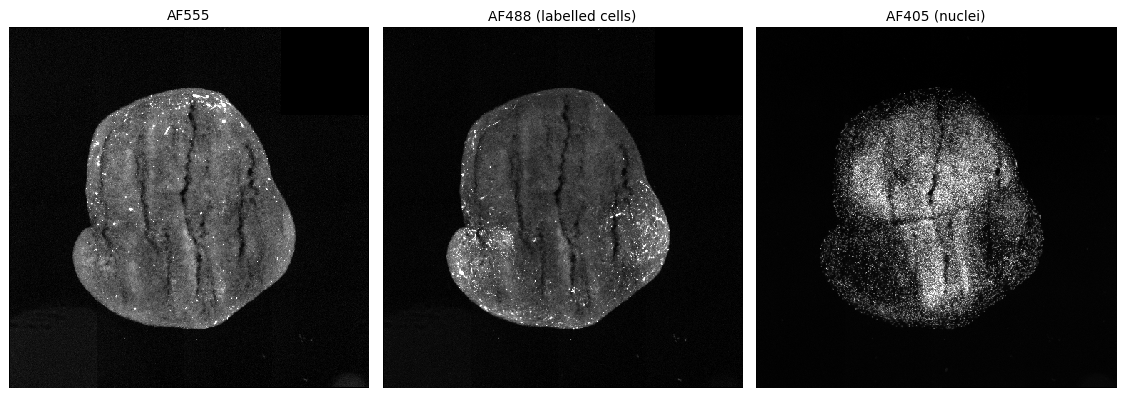

In [2]:
overview = jn.build_overview(specs, options)
um = overview.um
channels = overview.channels
nuclear, label = overview.nuclear, overview.label

print(f"full resolution : {overview.shape_yx[1]} x {overview.shape_yx[0]} px at {overview.voxel_yx[0]:.3f} µm")
print(f"overview        : {channels.shape[2]} x {channels.shape[1]} px at {um:.2f} µm  (every {overview.step}th pixel)")
print(f"nuclear channel : {overview.names[nuclear]}    labelled-cell channel : {overview.names[label]}")

fig, axes = plt.subplots(1, len(overview.names), figsize=(4.2 * len(overview.names), 4.6))
for ax, name, plane in zip(axes, overview.names, channels):
    tag = " (nuclei)" if name == overview.names[nuclear] else " (labelled cells)" if name == overview.names[label] else ""
    show(ax, stretch(plane), name + tag)
plt.tight_layout()
assert np.array_equal(channels, cached.channels)   # the overview the evaluation cached, pixel for pixel

## Step 1 — where the tissue is

From **every channel**, not only DAPI: each channel is smoothed over 10 µm and thresholded, a pixel is tissue if it stands above the slide in **any** of them, and the mask is then tidied (specks removed, small gaps closed) and debris smaller than a tenth of the largest piece dropped. An organoid whose nuclear stain is faint, common in one of a pair, is still bright in its own label or its autofluorescence; with DAPI alone it would be dropped, and the junction would stop where the mask does. This is `tissue_all_channels` (on by default since 22 October; panel: *Find the tissue in every channel*).

Each channel's threshold is deliberately **not** Otsu's midpoint. One organoid of a pair is often dimmer than the other, and the midpoint would drop the dim one. The cut sits a fifth of the way from the background level to the tissue level instead.

Two masks come out: `tissue` (holes left as holes: used for measuring) and `filled` (holes filled: used as the area the cut is made in). The middle panel shows what DAPI alone would have given: on this section it misses much of the labelled organoid, which is faint in DAPI.

tissue area 1.97 mm² (DAPI alone 1.67 mm²),  holes 0.0 % of it


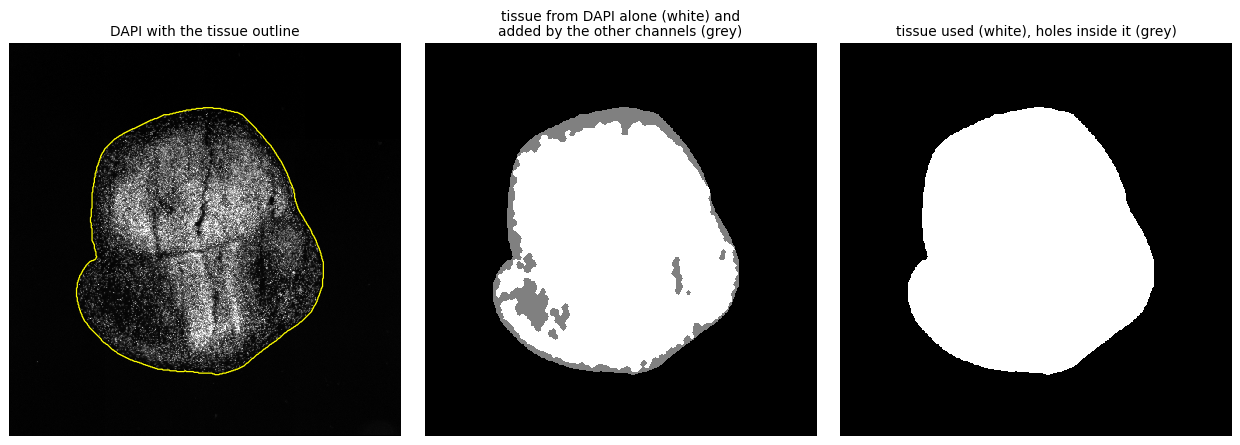

In [3]:
valid = (channels > 0).all(axis=0)          # stitched scans pad with exact zeros
others = jn._others(channels, nuclear, options.tissue_all_channels)    # the other channels, as find_junction passes them
tissue = jn.tissue_mask(channels[nuclear], valid, um, others)
filled = ndimage.binary_fill_holes(tissue)
dapi_only = jn.tissue_mask(channels[nuclear], valid, um)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
show(axes[0], stretch(channels[nuclear]), "DAPI with the tissue outline")
axes[0].contour(filled, [0.5], colors="yellow", linewidths=1)
show(axes[1], dapi_only.astype(int) + tissue, "tissue from DAPI alone (white) and\nadded by the other channels (grey)")
show(axes[2], tissue.astype(int) + filled, "tissue used (white), holes inside it (grey)")
plt.tight_layout()
print(f"tissue area {tissue.sum() * um * um / 1e6:.2f} mm² (DAPI alone {dapi_only.sum() * um * um / 1e6:.2f} mm²),  "
      f"holes {100 * (filled.sum() - tissue.sum()) / filled.sum():.1f} % of it")

## Step 2 — where the labelled cells are

The raw GFP channel is not a map of cells. It also holds autofluorescence, folds and thick parts of the section, which are bright but *diffuse*. A cell is a **point brighter than its surroundings**.

So: subtract a local median (45 µm) from the channel — diffuse signal goes with the median, points stay. The median can be switched off (`use_median=False`) or made wider or narrower (`median_um`); in the viewer that is *Take away the local median* in the Fusion region panel, and *Show the filter* puts the layers below on the canvas. The fourth panel is the density without it: wherever the channel is bright but holds no cells, it reads as cells. Then smooth what is left over 100 µm into a density map. The smoothing is normalised by the amount of tissue under the kernel, so the edge of the section is not mistaken for a drop in density.

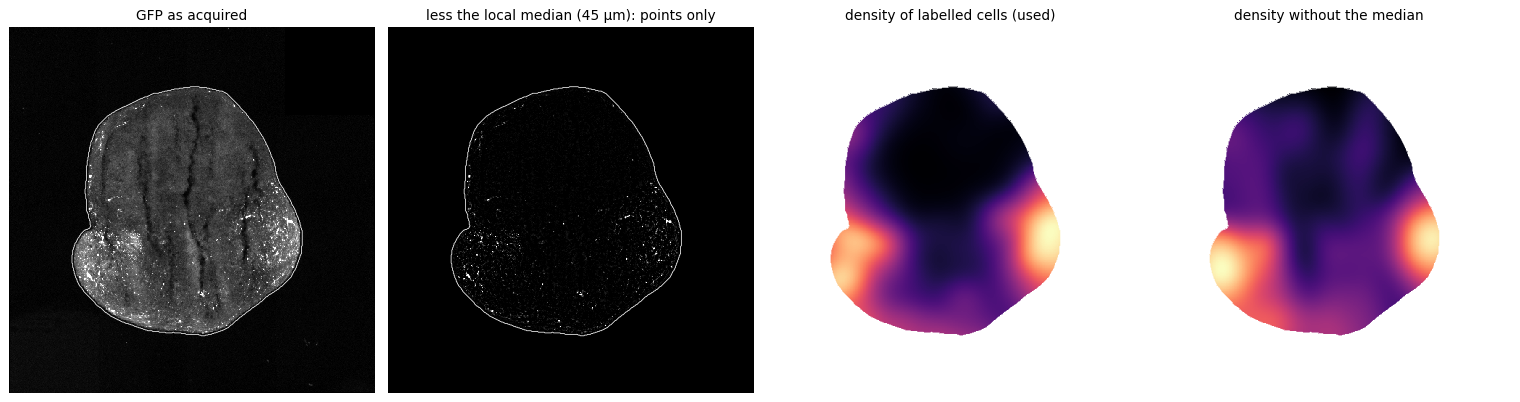

In [4]:
gfp = channels[label]
points = jn.cell_prominence(gfp, um, options.use_median, options.median_um)   # the channel less its local median
density = jn.cell_density(gfp, tissue, filled, um, median=options.use_median, median_um=options.median_um)
density_raw = jn.cell_density(gfp, tissue, filled, um, median=False)          # the same without the median

fig, axes = plt.subplots(1, 4, figsize=(17, 4.8))
show(axes[0], stretch(gfp), "GFP as acquired")
show(axes[1], stretch(points, 1, 99.9) * filled, f"less the local median ({options.median_um:.0f} µm): points only")
show(axes[2], np.where(filled, density, np.nan), "density of labelled cells (used)", cmap="magma")
show(axes[3], np.where(filled, density_raw, np.nan), "density without the median", cmap="magma")
for ax in axes:
    ax.contour(filled, [0.5], colors="white", linewidths=0.6)
plt.tight_layout()

## Step 3 — one seed in each organoid

The density map is good enough to say "this end is the labelled organoid". It is **not** good enough to draw the border: look how uneven it is inside the labelled organoid. So it is used only for a *seed* — a small area we are sure about — and the same is done for the other organoid.

**The same operation, once per organoid:**

| | Labelled organoid | Other organoid |
|---|---|---|
| Channel | GFP / 488 | the other label: mCherry / 555 |
| 1. Density of its cells | `cell_density` (step 2) | `cell_density`, same settings |
| 2. Dense core | largest patch above half its range | largest patch above half its range, outside the first core and where it outweighs GFP |
| 3. Pull back | keep the half furthest from the other seed | keep the half furthest from the other seed |

Step 3 of the table matters: a dense core reaches right up to the junction, and the cut would hug whichever seed is smaller. Distances are measured *through the tissue* (a straight line would call the far side of a hole close).

**Before this change** the second seed was not a positive sign of the second organoid, only the absence of the first: tissue with few GFP cells, far from the GFP core. That rule is still what is used when it has to be:

- the sample has no third channel;
- the other channel holds no cells (checked with `has_cells`: its brightest points must stand out over its own texture — otherwise its noise would be stretched into a "dense core");
- its dense core is tiny (under 2 % of the tissue) or sits where the GFP core is;
- `seed_from_other_channel=False` (panel: untick *Find the other organoid from its own label*).

Which rule was used is recorded per sample (`second_seed`, and the *Second seed* column of `junction_QC.xlsx`). Both are drawn below.

On this section the GFP density has two dense patches, one at each end of the labelled organoid; the seed is the larger one, at the lower left. Remember this for the failed section at the end.

other organoid's channel: AF555 | holds cells: True


second seed now   : dense core of the other organoid's label
second seed before: low-density tissue far from the labelled cells


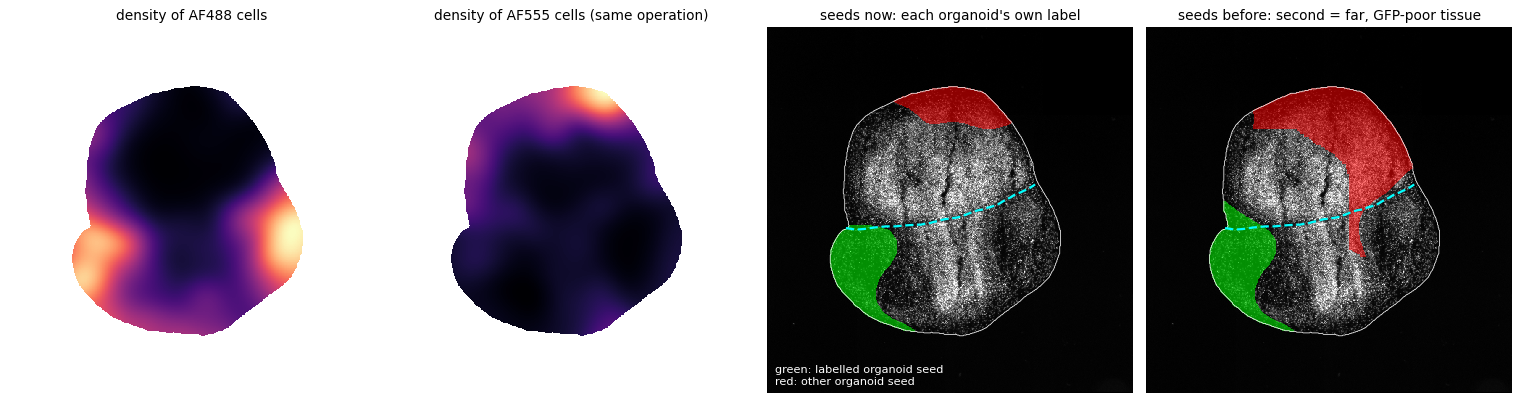

In [5]:
other = overview.other
other_density = None
if other is not None and jn.has_cells(channels[other], tissue, um):
    other_density = jn.cell_density(channels[other], tissue, filled, um)
print("other organoid's channel:", overview.names[other] if other is not None else "none",
      "| holds cells:", other_density is not None)

hot_seed, cold_seed, rule = jn.find_seeds(filled, density, other_density)      # what the viewer uses
hot_before, cold_before, rule_before = jn.find_seeds(filled, density, None)    # the rule before the change
print("second seed now   :", rule)
print("second seed before:", rule_before)

fig, axes = plt.subplots(1, 4, figsize=(17, 4.8))
show(axes[0], np.where(filled, density, np.nan), f"density of {overview.names[label]} cells", cmap="magma")
if other_density is not None:
    show(axes[1], np.where(filled, other_density, np.nan), f"density of {overview.names[other]} cells (same operation)", cmap="magma")
else:
    show(axes[1], np.zeros_like(density), "no usable other channel")
for ax, (a, b), title in ((axes[2], (hot_seed, cold_seed), "seeds now: each organoid's own label"),
                          (axes[3], (hot_before, cold_before), "seeds before: second = far, GFP-poor tissue")):
    show(ax, stretch(channels[nuclear]), title)
    ax.contour(filled, [0.5], colors="white", linewidths=0.6)
    ax.contourf(a, [0.5, 1.5], colors=["lime"], alpha=0.55)
    ax.contourf(b, [0.5, 1.5], colors=["red"], alpha=0.55)
    hand(ax, manual_line_um, um)
axes[2].text(0.02, 0.02, "green: labelled organoid seed\nred: other organoid seed", transform=axes[2].transAxes, color="white", fontsize=9, va="bottom")
plt.tight_layout()

## Step 4 — the price of cutting: follow the dark DAPI line

Between two fused organoids DAPI shows a thin dark line (or an edge, where a dim organoid lies against a bright one). To make the cut follow it, every pixel gets a **cost**:

$$\text{cost} = \left(\frac{\text{DAPI smoothed over 8 µm}}{\text{DAPI smoothed over 60 µm}}\right)^{6}$$

- In the middle of either organoid the ratio is 1, whether that organoid is bright or dim — so brightness differences between the two do not matter.
- On anything darker than its surroundings the ratio drops below 1.
- The power 6 makes that count: a line 20 % darker than its surroundings costs about a quarter as much to cut as plain tissue.

Outside the tissue the cost is set to the tissue's own level, so the section's edge is not itself a "dark line".

On this section the hand-drawn junction (cyan) runs along a ribbon of cheap pixels. The vertical cracks across the upper organoid are cheap too, and so is the rim of the section.

mean price under the hand-drawn line: 0.37 (plain tissue: 1)


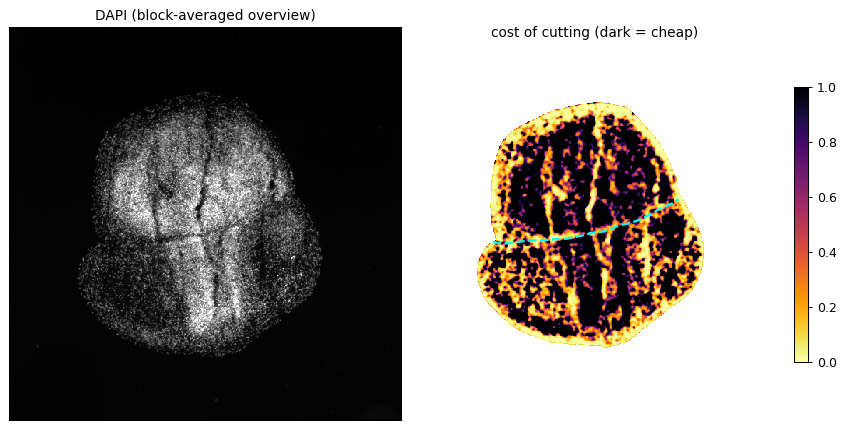

In [6]:
stain = overview.nuclear_mean if overview.nuclear_mean is not None else channels[nuclear]
cost = jn.line_cost(stain, filled, um)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.8))
show(axes[0], stretch(stain), "DAPI (block-averaged overview)")
image = axes[1].imshow(np.where(filled, cost, np.nan), cmap="inferno_r", vmin=0, vmax=1)
axes[1].set_title("cost of cutting (dark = cheap)")
axes[1].set_axis_off()
plt.colorbar(image, ax=axes[1], fraction=0.035)
hand(axes[1], manual_line_um, um)
plt.tight_layout()
on_line = np.round(jt.dense(manual_line_um) / um).astype(int)
on_line = on_line[filled[on_line[:, 0], on_line[:, 1]]]
print(f"mean price under the hand-drawn line: {cost[on_line[:, 0], on_line[:, 1]].mean():.2f} (plain tissue: 1)")

## Step 5 — the minimum cut

Now the tissue is treated as a graph: every pixel is joined to its eight neighbours, and cutting a join costs the mean of the two pixels' cost. The **minimum cut** is the cheapest set of joins to cut so that the two seeds end up on different sides.

Why this works:

- With a uniform cost, the cheapest cut is simply the *shortest* way across the tissue between the seeds: it finds the neck between two lobes, or else goes round the smaller seed.
- With the DAPI cost, running along a dark line is cheaper than running through plain tissue, so the cut bends onto the line.
- The cost is summed over the **whole** cut. A single dark speck saves one pixel's worth; a continuous dark line saves all of it. That is what makes the cut follow a line and ignore specks.

Below, the same cut with and without the DAPI cost. On this section neither is right yet. By shape alone (magenta) the cut is the shortest way round the second seed, across the top of the other organoid. With the DAPI cost (yellow) it follows the junction from the left edge, then turns a corner and runs **down a crack** to the lower edge: a crack is a dark line too, and the cut only adds up what it crosses. Step 5b deals with that. The raw cut is jagged, made pixel by pixel, which is what step 6 deals with.

cut by shape alone: line a mean 607 µm from the hand-drawn one
cut along the DAPI line: line a mean 312 µm from the hand-drawn one
cut with the second seed as it was before: differs from the cut used on 72 overview pixels (a different cut)


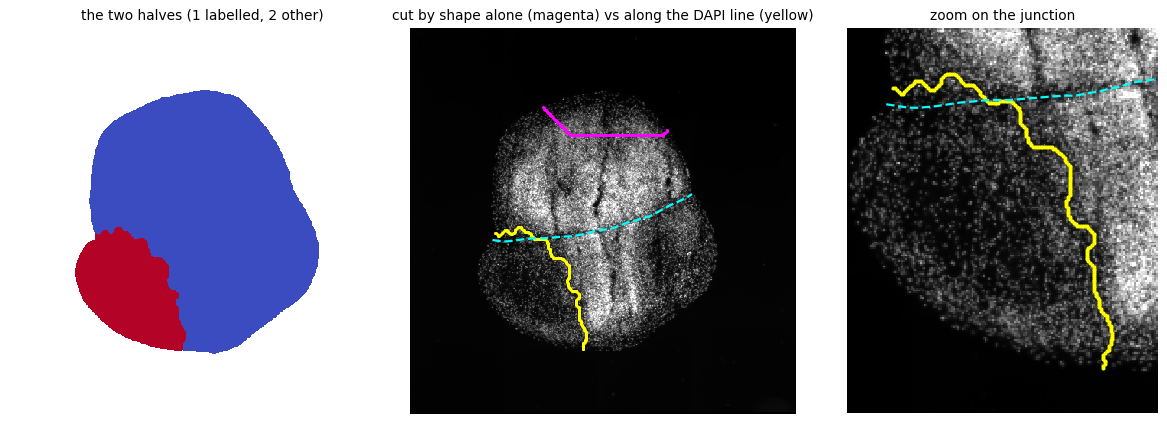

In [7]:
halves = jn.split_tissue(filled, density, um, cost, seeds=(hot_seed, cold_seed))          # the minimum cut alone
halves_shape_only = jn.split_tissue(filled, density, um, None, seeds=(hot_seed, cold_seed))
halves_before = jn.split_tissue(filled, density, um, cost, seeds=(hot_before, cold_before))  # with the second seed as it was

def boundary(h):
    return (h == 1) & ndimage.binary_dilation(h == 2)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.8))
show(axes[0], np.where(halves > 0, halves, np.nan), "the two halves (1 labelled, 2 other)", cmap="coolwarm_r")
show(axes[1], stretch(stain), "cut by shape alone (magenta) vs along the DAPI line (yellow)")
for h, colour in ((halves_shape_only, "magenta"), (halves, "yellow")):
    rows, cols = np.nonzero(boundary(h))
    axes[1].scatter(cols, rows, s=2, c=colour)
hand(axes[1], manual_line_um, um)
rows, cols = np.nonzero(boundary(halves))
pad = 25
r0, r1, c0, c1 = max(rows.min() - pad, 0), rows.max() + pad, max(cols.min() - pad, 0), cols.max() + pad
show(axes[2], stretch(stain)[r0:r1, c0:c1], "zoom on the junction")
for h, colour in ((halves_shape_only, "magenta"), (halves, "yellow")):
    rr, cc = np.nonzero(boundary(h)[r0:r1, c0:c1])
    axes[2].scatter(cc, rr, s=5, c=colour)
hand(axes[2], manual_line_um, um, offset=(r0, c0))
axes[2].set_xlim(0, c1 - c0); axes[2].set_ylim(r1 - r0, 0)
plt.tight_layout()
for name, h in (("by shape alone", halves_shape_only), ("along the DAPI line", halves)):
    print(f"cut {name}: line a mean {off_by(jn.trace_interface(h, um) * um, filled, um):.0f} µm from the hand-drawn one")

if halves_before is not None:
    moved = boundary(halves) ^ boundary(halves_before)
    print(f"cut with the second seed as it was before: differs from the cut used on {int(moved.sum())} overview pixels"
          f" ({'same cut' if not moved.any() else 'a different cut'})")

## Step 5b — straighten the cut: turning costs

A minimum cut only adds up what it crosses. It has no idea of direction, so a **crack or a tear** — the darkest, cheapest thing in the section — is as good a road as the line between the organoids, and the cut will turn a right angle to follow one.

So the cut is found a second time, as a curve that pays for every turn. Lay stations across the section, perpendicular to the axis from one seed to the other, 20 µm apart; at each station the curve sits somewhere between the seeds (in 5 µm steps). Its cost is what it crosses (the same price as before, per µm, and nothing off the tissue) **plus `bend_um` × (turn ÷ 90°)²** at every station. That is bending energy: one sharp corner costs a lot, the same turn spread along the curve costs little — so it still curves round an organoid, but no longer turns a corner. The cheapest such curve over the whole section is found exactly by dynamic programming over (position, heading). The halves are then the two sides of it.

`bend_um` is 1000 by default: a sharp 90° corner costs as much as cutting 1000 µm of plain tissue. That value was chosen on hand-drawn junctions ([junction_evaluation.ipynb](../validation/junction_evaluation.ipynb)): against 400 it keeps the median and pulls in the worst samples. 0 gives the minimum cut alone. In the viewer: *Bending cost* in the Fusion region panel.

On this section it is what puts the line on the junction: the cut no longer turns down the crack.

minimum cut alone: line a mean 312 µm from the hand-drawn one
bending costed: line a mean 15 µm from the hand-drawn one


sharpest turn of the junction line: 21° alone, 4° with bending costed; the two cuts differ on 492 overview pixels


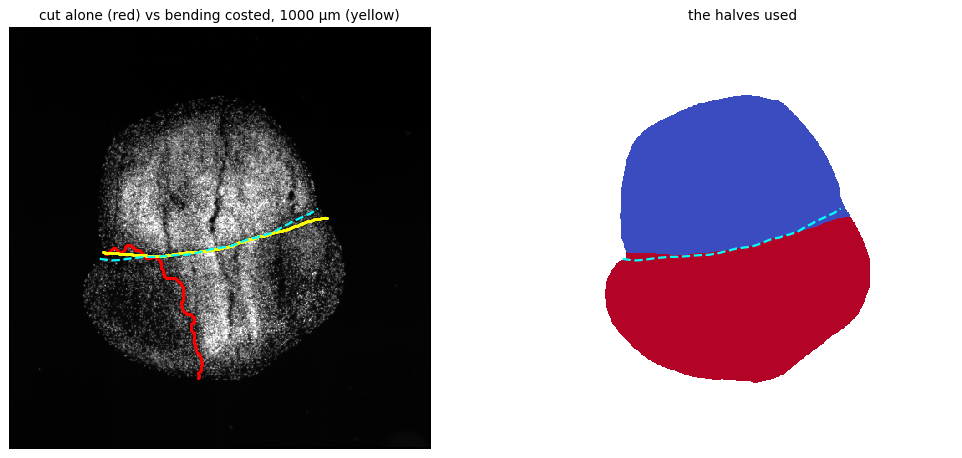

In [8]:
halves_free = halves                                        # step 5: the minimum cut alone
halves = jn.split_tissue(filled, density, um, cost, seeds=(hot_seed, cold_seed), bend_um=options.bend_um)  # what the viewer uses


def sharpest_turn(h):
    line = jn.trace_interface(h, um)
    v = np.diff(line, axis=0)
    heading = np.unwrap(np.arctan2(v[:, 0], v[:, 1]))
    return float(np.degrees(np.abs(np.diff(heading)).max())) if len(heading) > 1 else 0.0


fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
show(axes[0], stretch(stain), f"cut alone (red) vs bending costed, {options.bend_um:.0f} µm (yellow)")
for h, colour in ((halves_free, "red"), (halves, "yellow")):
    rows, cols = np.nonzero(boundary(h))
    axes[0].scatter(cols, rows, s=2, c=colour)
show(axes[1], np.where(halves > 0, halves, np.nan), "the halves used", cmap="coolwarm_r")
for ax in axes:
    hand(ax, manual_line_um, um)
plt.tight_layout()
moved = boundary(halves) ^ boundary(halves_free)
for name, h in (("minimum cut alone", halves_free), ("bending costed", halves)):
    print(f"{name}: line a mean {off_by(jn.trace_interface(h, um) * um, filled, um):.0f} µm from the hand-drawn one")
print(f"sharpest turn of the junction line: {sharpest_turn(halves_free):.0f}° alone, {sharpest_turn(halves):.0f}° with bending costed; "
      f"the two cuts differ on {int(moved.sum())} overview pixels")

## Step 6 — from the cut to a junction line

The cut is found pixel by pixel and wanders by a few pixels. An organoid boundary does not. So:

1. Take the pixels where half 1 touches half 2 and thin them to a one-pixel curve.
2. Order the curve end to end (the two ends are the two points furthest apart along it).
3. Smooth it along its length with a running mean over 150 µm, and keep a point every 40 µm.

The result is the **junction line**, in micrometres. This is exactly what goes into the *Fusion line* layer in the viewer, where it can be dragged or redrawn.

the junction line is a mean 15 µm from the hand-drawn one (cyan dashes)
34 points, junction length 1286 µm


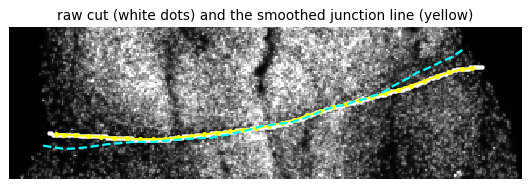

In [9]:
line_px = jn.trace_interface(halves, um)       # (row, col) in overview pixels
line_um = line_px * um

rows, cols = np.nonzero(boundary(halves))          # zoom on the cut used
pad = 25
r0, r1, c0, c1 = max(rows.min() - pad, 0), rows.max() + pad, max(cols.min() - pad, 0), cols.max() + pad
fig, ax = plt.subplots(figsize=(6, 5.2))
show(ax, stretch(stain)[r0:r1, c0:c1], "raw cut (white dots) and the smoothed junction line (yellow)")
rr, cc = np.nonzero(boundary(halves)[r0:r1, c0:c1])
ax.scatter(cc, rr, s=6, c="white")
ax.plot(line_px[:, 1] - c0, line_px[:, 0] - r0, "-o", color="yellow", ms=3, lw=1.5)
hand(ax, manual_line_um, um, offset=(r0, c0))
ax.set_xlim(0, c1 - c0); ax.set_ylim(r1 - r0, 0)
plt.tight_layout()
print(f"the junction line is a mean {off_by(line_um, filled, um):.0f} µm from the hand-drawn one (cyan dashes)")
print(f"{len(line_um)} points, junction length {fu.line_length(fu.fit_spline(line_um, spacing=um)):.0f} µm")

## Step 7 — the band

The band is **every part of one organoid that lies within the band width of the junction line**:

- *which organoid*: by default the one the labelled cells migrate **into** (the unlabelled one). `into_unlabelled=False` puts it on the labelled organoid instead.
- *how far*: from `gap_um` (2 µm, so the line itself is not counted) to `gap_um + width_um` (here 300 µm, the width the hand-drawn band of this section was made with), measured as distance from the line.
- *clipped to the tissue*, and everything rounded off over 25 µm.
- *plus a rim past the tissue's edge* (`margin_um`, 10 µm): cells migrating out over the organoid's surface sit just outside the outline the DAPI stain gives, and would be missed. The rim goes with the organoid it borders and never into the other organoid's tissue. In the viewer: *Past the tissue edge*.

This is different from the original Fiji macro, which pushes the line sideways to make a strip. A strip ends in two straight cuts across the tissue wherever the line happened to stop. Taking the organoid's own tissue by distance lets the band end where the organoid ends: its two extremities follow the organoid's outline. Both are drawn below.

In the third panel the band stored with the hand-drawn line is outlined in cyan dashes. On this section it was made as the macro's strip (*Follow the tissue* off), so its ends are straight and reach past the outline; the overlap is measured on the tissue only.

overlap with the hand-drawn band, on the tissue (Dice): 0.94
band on the side: Left of the line   area 0.395 mm²


of which past the tissue's edge (the 10 µm rim): 0.004 mm²; without the rim the band is 0.390 mm²


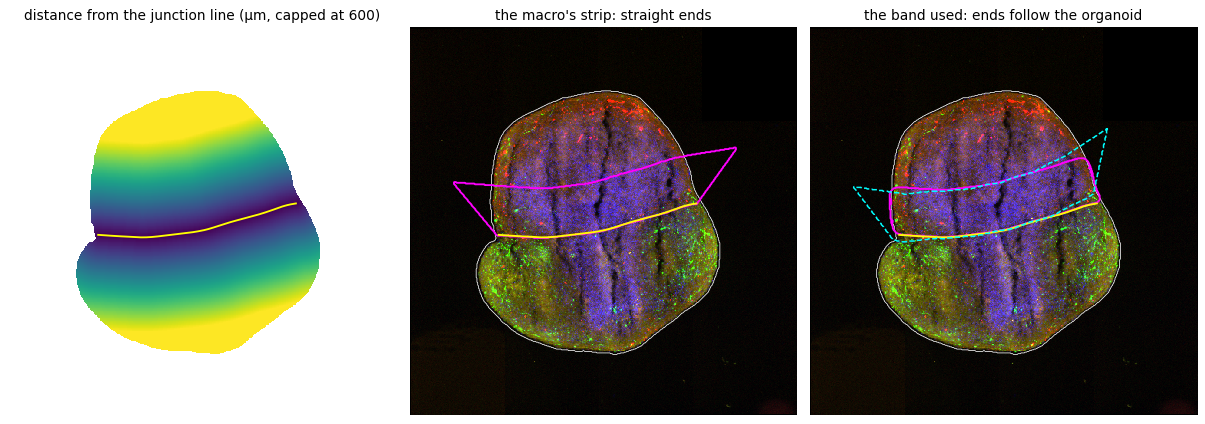

In [10]:
result = jn.find_junction(overview, options)      # steps 1-7 in one call, as the viewer does it
band = result.band

curve = fu.fit_spline(result.line_um, spacing=um)
on_line = jn._draw_curve(curve / um, filled.shape)
distance = ndimage.distance_transform_edt(~on_line) * um

strip, _ = fu.fusion_region(result.line_um, filled.shape, (um, um), width_um=options.width_um,
                            gap_um=options.gap_um, side=result.side)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.8))
show(axes[0], np.where(filled, np.minimum(distance, 600), np.nan), "distance from the junction line (µm, capped at 600)", cmap="viridis")
axes[0].plot(curve[:, 1] / um, curve[:, 0] / um, color="yellow", lw=1.5)
rgb = np.dstack([stretch(channels[[i for i in range(len(channels)) if i not in (nuclear, label)][0]]) if len(channels) > 2 else np.zeros_like(stain),
                 stretch(channels[label]), stretch(channels[nuclear])])
for ax, mask, title in ((axes[1], strip > 0, "the macro's strip: straight ends"), (axes[2], band, "the band used: ends follow the organoid")):
    show(ax, rgb, title)
    ax.contour(filled, [0.5], colors="white", linewidths=0.6)
    ax.contour(mask, [0.5], colors="magenta", linewidths=1.5)
    ax.plot(curve[:, 1] / um, curve[:, 0] / um, color="yellow", lw=1.5)
axes[2].contour(manual_band, [0.5], colors="cyan", linewidths=1.2, linestyles="dashed")
plt.tight_layout()
assert np.array_equal(result.halves, halves)     # the same halves as the steps above
on = manual_band & filled
print(f"overlap with the hand-drawn band, on the tissue (Dice): {2 * (band & on).sum() / ((band & filled).sum() + on.sum()):.2f}")
print(f"band on the side: {result.side}   area {band.sum() * um * um / 1e6:.3f} mm²")
bare = jn.find_junction(overview, jn.JunctionOptions(**{**options.__dict__, "margin_um": 0.0})).band
print(f"of which past the tissue's edge (the {options.margin_um:.0f} µm rim): {(band & ~filled).sum() * um * um / 1e6:.3f} mm²; "
      f"without the rim the band is {bare.sum() * um * um / 1e6:.3f} mm²")

## Step 8 — back to full resolution

Cells are segmented and measured at full resolution, so the band has to go back onto the image's own pixel grid. Enlarging the overview mask would give a staircase, each step as wide as the shrink factor (15 pixels here). Instead the band's **outline** (a polygon in micrometres) is filled on the full grid, which stays smooth at any pixel size.

This full-resolution label map is what is stored with the sample as *fusion region*, and what the Junction analysis panel counts cells in.

label map 7567 x 7584 px, band covers 0.396 mm²


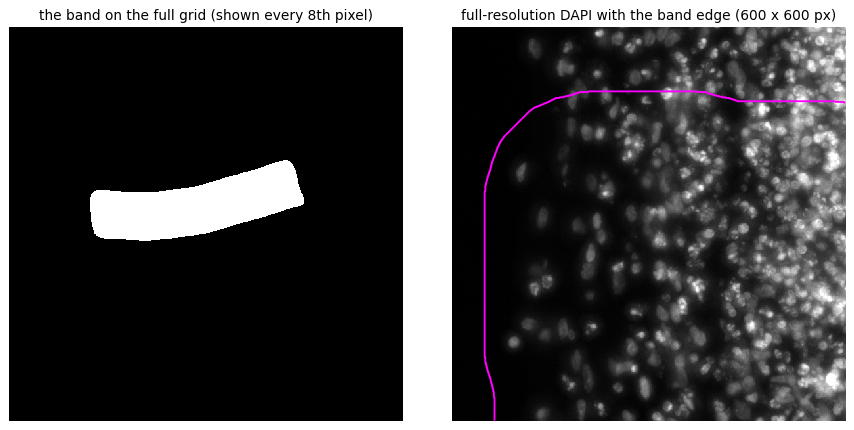

In [11]:
labels = jn.full_resolution_band(result, overview, options)
rows, cols = np.nonzero(labels.any(axis=1))[0], np.nonzero(labels.any(axis=0))[0]
print(f"label map {labels.shape[1]} x {labels.shape[0]} px, band covers {labels.sum() * np.prod(overview.voxel_yx) / 1e6:.3f} mm²")

# A 600 x 600 px window at full resolution on the band's edge, to show the outline is smooth.
cy, cx = int(rows.mean()), int(cols[0]) + 250
window = (slice(max(cy - 300, 0), cy + 300), slice(max(cx - 300, 0), cx + 300))
dapi_full = np.asarray(specs[nuclear].data).reshape((-1, *overview.shape_yx)).max(axis=0)[window]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
show(axes[0], labels[::8, ::8], "the band on the full grid (shown every 8th pixel)")
show(axes[1], stretch(np.asarray(dapi_full, dtype=np.float32) + 1), "full-resolution DAPI with the band edge (600 x 600 px)")
axes[1].contour(labels[window], [0.5], colors="magenta", linewidths=1.5)
plt.tight_layout()

## Step 9 — how far to trust it

A line can be put through anything, including a torn section or two organoids that never fused. So every sample is scored from figures measured along the way, and gets a status:

- **fail** — unusable: no tissue, organoids not fused, or no junction found.
- **check** — a junction was found but something is worth a look.
- **ok** — nothing flagged.

| Flag | Raised when | Status |
|---|---|---|
| no tissue found | tissue area is zero | fail |
| organoids not fused | a second piece ≥ 25 % of the largest | fail |
| no junction found | no seeds, or no cut | fail |
| large holes or torn | holes > 10 % of the section | check |
| ragged outline | solidity (area / convex hull) < 0.75 | check |
| cut off by the scan edge | > 5 % of the outline on the edge of the scan | check |
| saturated | > 1 % of DAPI at the detector maximum | check |
| junction very short | < 150 µm | check |
| no dark line at the junction | seam price (the mean price under the cut, step 4) > 0.4 | check |
| labelled cells on both sides (junction uncertain) | density ratio across the junction < 1.8 | check |
| one organoid much smaller than the other | labelled half < 10 % or > 90 % of the tissue | check |
| hardly any tissue in the band | < 0.02 mm² | check |
| size / staining unlike the rest, out of focus | > 3.5 robust SDs from the folder (needs 8+ samples) | check |

**What "ok" does and does not mean.** It means none of these checks fired. It does **not** certify that the line is where a person would draw it. That is what the QC pictures and the *Junction review* panel are for.

Alongside the figures behind these flags, `tissue_metrics` records the section's **shape** (perimeter, long and short axis, four shape numbers that do not change with size or rotation) and `result.signature` a small picture of its outline; those are for matching serial sections of one assembloid, and no flag reads them.

In [12]:
print(f"status: {result.status.upper()}    flags: {'; '.join(result.flags) or 'none'}\n")
for key, value in result.metrics.items():
    print(f"  {key:36s} {value:12.4g}")

status: OK    flags: none

  Tissue area (mm2)                           1.965
  Focus                                     0.02159
  Saturated fraction                              0
  Pieces                                          1
  Second piece share                              0
  Hole share                                      0
  Solidity                                   0.9828
  Cut off by the scan                             0
  Nuclear stain (mean)                         1916
  Perimeter (um)                               5415
  Major axis (um)                              1695
  Minor axis (um)                              1496
  Shape 1                                     0.789
  Shape 2                                     3.389
  Shape 3                                     3.936
  Shape 4                                     6.405
  Split                                           0
  Cut price                                   0.308
  Sharpest turn (deg)                

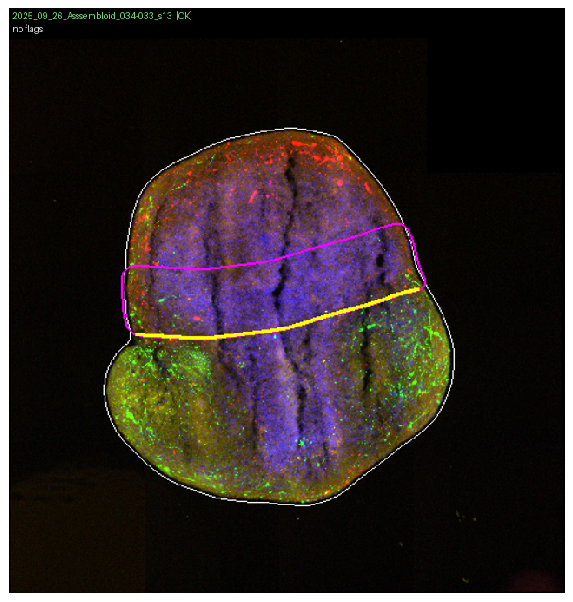

In [13]:
# The QC picture a run writes for this sample: outline white, junction yellow, band magenta.
picture = jn.qc_picture(overview, result, jn.fu_name(SAMPLE))
fig, ax = plt.subplots(figsize=(6.5, 6.8))
ax.imshow(picture)
ax.set_axis_off()
plt.tight_layout()

## A line drawn by hand

When the automatic line is wrong it is redrawn by hand (*Junction review* or the *Fusion region* panel). A drawn line used to get the Fiji macro's strip; with **Follow the tissue** (on by default) it gets a band made the way step 7 makes one: the organoid's own tissue within the band width of the line, ends following the outline, plus the rim. `band_along_tissue` does it, from the overview of the sample and the line as drawn — no labels, no cut: which side is which comes from the macro's two strips, and the tissue is divided between them along the line.

It is stored as **`manual annotated junction region`**, beside the automatic `fusion region` rather than over it. Junction analysis and the manual positive count use the hand-drawn region where a sample has one, and the automatic band where it does not, and say which.

Below, the line actually drawn on this section (cyan dashes), made into a band both ways with the settings stored with it, and each compared on the tissue with the band that was stored (on this section, made as the macro's strip).

macro's strip          remade from the drawn line vs the band stored with it, on the tissue (Dice): 0.98
band along the tissue  remade from the drawn line vs the band stored with it, on the tissue (Dice): 0.99
stored as “manual annotated junction region”; the automatic band as “fusion region”


1

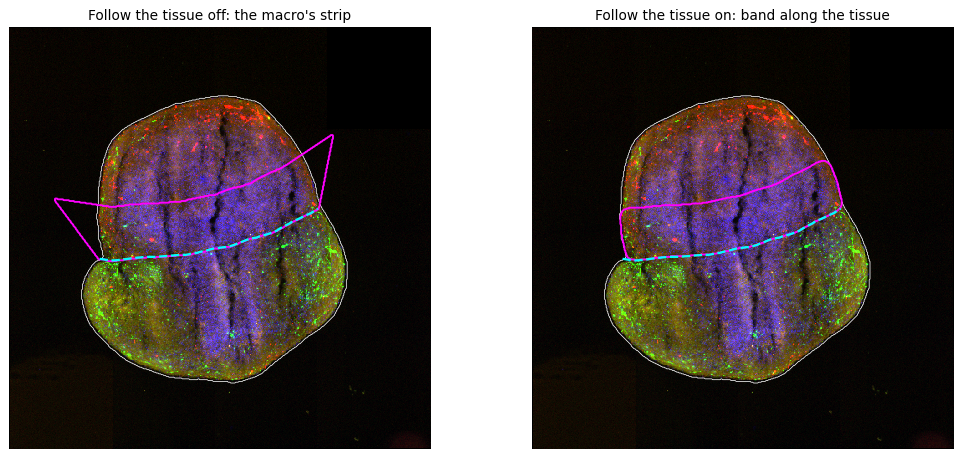

In [14]:
side = result.side                                  # the band goes on the unlabelled organoid, as the automatic one
labels_drawn = jn.band_along_tissue(overview, filled, manual_line_um, side, base["width_um"], base["gap_um"], base["margin_um"])
strip_drawn, _ = fu.fusion_region(manual_line_um, filled.shape, (um, um), width_um=base["width_um"], gap_um=base["gap_um"], side=side)
followed = labels_drawn[::overview.step, ::overview.step][: filled.shape[0], : filled.shape[1]] > 0

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, mask, title in ((axes[0], strip_drawn > 0, "Follow the tissue off: the macro's strip"),
                        (axes[1], followed, "Follow the tissue on: band along the tissue")):
    show(ax, rgb, title)
    ax.contour(filled, [0.5], colors="white", linewidths=0.6)
    ax.contour(mask, [0.5], colors="magenta", linewidths=1.5)
    hand(ax, manual_line_um, um)
plt.tight_layout()
on = manual_band & filled
for name, mask in (("macro's strip", strip_drawn > 0), ("band along the tissue", followed)):
    mask = mask & filled
    print(f"{name:22s} remade from the drawn line vs the band stored with it, on the tissue (Dice): "
          f"{2 * (mask & on).sum() / (mask.sum() + on.sum()):.2f}")
print(f"stored as “{fu.MANUAL_KEY}”; the automatic band as “{fu.DEFAULT_KEY}”")
loaders.release(SAMPLE)

## All of it in one call

The steps above are what these do:

```python
overview, result = jn.analyse_specs(loaders.load_path(path), options)   # one sample, nothing written
outcome  = jn.process_file(path, options)                                # + store the band, + QC picture
outcomes = jn.run(paths, options)                                        # a folder: + cohort checks, workbook, contact sheets
```

In the viewer: **Fusion region** panel → *Find the junction automatically* (one sample) or *Run on the selected samples* (a folder).

## The settings that matter

| Setting | Default | What it changes |
|---|---|---|
| `width_um` | 300 | how far the band reaches from the junction |
| `gap_um` | 2 | distance left between the line and the band |
| `into_unlabelled` | True | band on the organoid cells migrate into; False puts it on the labelled one |
| `follow_nuclear_line` | True | use the DAPI cost (step 4); False cuts by shape alone |
| `bend_um` | 1000 | what a sharp 90° corner in the junction costs, in µm of plain tissue (step 5b); 0 = the minimum cut alone |
| `tear_price` | 0 (off) | price of cutting along a tear — a hole, or stain under 35 % of the tissue's level; 1 = like plain tissue. Made no measurable difference on the hand-drawn set |
| `edge_weight` | 0 (off) | extra price for cutting where the labelled cells do not change. Made the line *worse* on the hand-drawn set: the labelled cells' density does not change at the junction in these sections |
| `use_median`, `median_um` | True, 45 | take the local median away from the label channels before counting cells (step 2) |
| `margin_um` | 10 | how far the band reaches past the tissue's edge (step 7) |
| `tissue_all_channels` | True | find the tissue in every channel, not only DAPI (step 1) |
| `seed_rule` | "core" | "dominant": each seed is all the tissue where its own label clearly leads; better held out, worse on the tuning set, so off |
| `no_seam_price` | 0.4 (on since 26 Oct) | above this seam price, find the junction again from dominant seeds; held-out error 172 → 159 µm on 138 hand-drawn sections (`junction_seeding.ipynb`) |
| `split_method` | "cut" | "walk" (random walker) or "auto"; tried, not better |
| `seed_from_other_channel` | True | second seed from the other organoid's label (step 3); False uses the far, GFP-poor tissue |
| `other_channel` | by name: mCherry/555/561, else the channel left over | which channel labels the other organoid |
| `clip_to_tissue` | True | keep only the part of the band on tissue |
| `nuclear_channel`, `label_channel` | by name: DAPI/Hoechst/405, GFP/488 | which channels play the first two roles |

Constants in `junction.py`: overview pixel 5 µm, DAPI smoothing 8 µm against 60 µm, cost power 6, junction smoothing 150 µm, outline smoothing 25 µm.

## Where it goes wrong

- **A crack or fold is a dark line too** — a tear even more so: it is empty, the darkest and so the cheapest thing to cut along. Step 5b stops the cut from turning a corner to follow one (as on the section above), but where a long tear leads from the junction to the edge and the seed is small, it can still win: see the next section.
- **Labelled cells on both sides.** If cells have spread widely, or the label is everywhere, the density map cannot say which organoid is which and the seeds can land in the wrong place. This raises the *labelled cells on both sides* flag — the most common flag in this dataset.
- **A label that sits along one edge.** The second seed only needs to be *in* the right organoid, so an edge label is enough to place it. But a small seed at the far edge leaves the cut freer than a large one: on about a third of the sections of this dataset the junction moved by more than 100 µm when the second seed changed from the far tissue to the 555 core. Look at the QC pictures after changing this setting.
- **One organoid embedded in the other.** There is no neck and often no continuous dark line; the cut is then a guess.
- **No dark line at all.** The cut falls back on being the shortest way across, which is right for two lobes with a neck and arbitrary otherwise. The *no dark line at the junction* flag (seam price above 0.4) marks these, and the junction is then found a second time from dominant seeds: each seed is all the tissue where its own label clearly leads, so the cut is left only the mixed strip between them. It helps, but half such lines are still more than 100 µm off: draw them by hand.
- **The band is 2D.** It is built on a maximum projection; a junction that tilts through the section thickness is drawn where it projects.

When the line is wrong, redraw it by hand: *Junction review* panel → mark *Redraw* → draw → *Save and next*. The hand-drawn band is stored as `manual annotated junction region` and is used in preference to the automatic one for that sample.

## A section where it fails: `..._s17`

The same slide, a few sections further on: same assembloid, same staining. The finder reports **ok** with no flag, yet its line lies about 340 µm from the hand-drawn one. Below, the steps that matter on it, from the cached overview, with the worked section above for comparison.

1. **The section**: the two lines over the three channels. The upper organoid has long, open **tears** (dark slits in DAPI with no tissue in them).
2. **Seeds** (step 3): as on the worked section, the GFP density has a dense patch at each end of the labelled organoid, and the labelled seed (green) is only the larger, lower-left one.
3. **Price and cuts** (steps 4, 5, 5b): the tears are the cheapest pixels of the section. The minimum cut (red) and the cut with bending costed (yellow) both run from the left edge along the junction, then **down the long tear** to the lower edge, wrapping round the small seed.

minimum cut           : line a mean 321 µm from the hand-drawn one
bending costed (used) : line a mean 341 µm from the hand-drawn one
hand-drawn line       : mean price under it 0.50, 11 % of it on a tear
finder's line         : mean price under it 0.22, 29 % of it on a tear
labelled share 0.20 (flag below 0.10), density contrast 1.90 (flag below 1.8), seam price 0.23 (flag above 0.4)


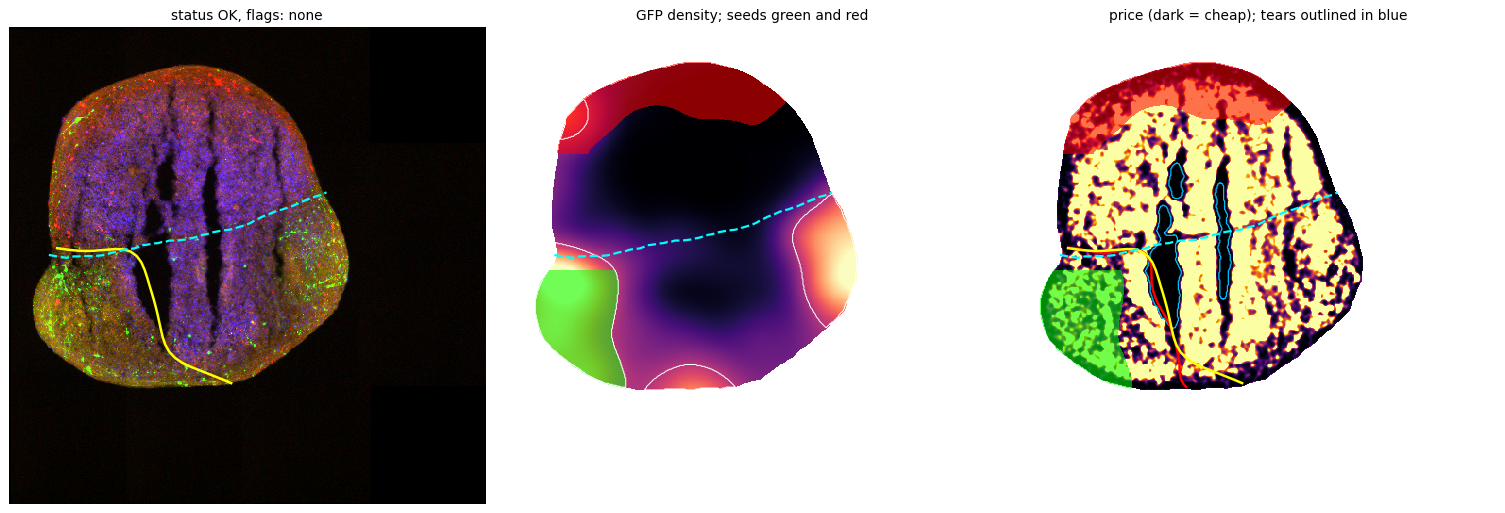

In [15]:
F_overview, F_band, F_line, F_base = jt.load_case(FAILED)
F_options = jn.JunctionOptions(width_um=F_base["width_um"], gap_um=F_base["gap_um"], save=False)
F = jn.find_junction(F_overview, F_options)
Fu, Fc = F_overview.um, F_overview.channels
F_cost = jn.line_cost(F_overview.nuclear_mean, F.filled, Fu)
F_hot, F_cold = F.seeds
F_free = jn.split_tissue(F.filled, F.density, Fu, F_cost, seeds=(F_hot, F_cold))
F_lines = {"minimum cut": jn.trace_interface(F_free, Fu) * Fu, "bending costed (used)": F.line_um}

fig, axes = plt.subplots(1, 3, figsize=(17, 5.6))
show(axes[0], np.dstack([stretch(Fc[F_overview.other]), stretch(Fc[F_overview.label]), stretch(Fc[F_overview.nuclear])]),
     f"status {F.status.upper()}, flags: {'; '.join(F.flags) or 'none'}")
axes[0].plot(F.line_um[:, 1] / Fu, F.line_um[:, 0] / Fu, color="yellow", lw=2)
show(axes[1], np.where(F.filled, jn._normalised(F.density, F.filled), np.nan), "GFP density; seeds green and red", cmap="magma")
axes[1].contour(jn._normalised(F.density, F.filled) > 0.5, [0.5], colors="white", linewidths=0.8)
show(axes[2], np.where(F.filled, F_cost, np.nan), "price (dark = cheap); tears outlined in blue", cmap="inferno", vmin=0, vmax=1)
axes[2].contour(F.filled & ~F.tissue, [0.5], colors="deepskyblue", linewidths=1)
for ax in axes[1:]:
    ax.contourf(F_hot, [0.5, 1.5], colors=["lime"], alpha=0.55)
    ax.contourf(F_cold, [0.5, 1.5], colors=["red"], alpha=0.55)
for name, colour in (("minimum cut", "red"), ("bending costed (used)", "yellow")):
    line = F_lines[name]
    axes[2].plot(line[:, 1] / Fu, line[:, 0] / Fu, color=colour, lw=2)
for ax in axes:
    hand(ax, F_line, Fu)
plt.tight_layout()
for name, line in F_lines.items():
    print(f"{name:22s}: line a mean {off_by(line, F.filled, Fu, F_line):.0f} µm from the hand-drawn one")
for name, line in (("hand-drawn line", F_line), ("finder's line", F.line_um)):
    rc = np.round(jt.dense(line) / Fu).astype(int)
    rc = rc[F.filled[rc[:, 0], rc[:, 1]]]
    print(f"{name:22s}: mean price under it {F_cost[rc[:, 0], rc[:, 1]].mean():.2f}, "
          f"{100 * (F.filled & ~F.tissue)[rc[:, 0], rc[:, 1]].mean():.0f} % of it on a tear")
print(f"labelled share {F.metrics['Labelled share of tissue']:.2f} (flag below 0.10), density contrast "
      f"{F.metrics['Density contrast']:.2f} (flag below 1.8), seam price {F.metrics['Seam price']:.2f} (flag above 0.4)")

**Which change rescues it?** One thing changed at a time: the labelled seed also covering the GFP patch at the other end of the labelled organoid; tears priced as plain tissue (`tear_price=1`); dominant seeds (`seed_rule="dominant"`). Each panel shows that run's seeds and line over the default price map.

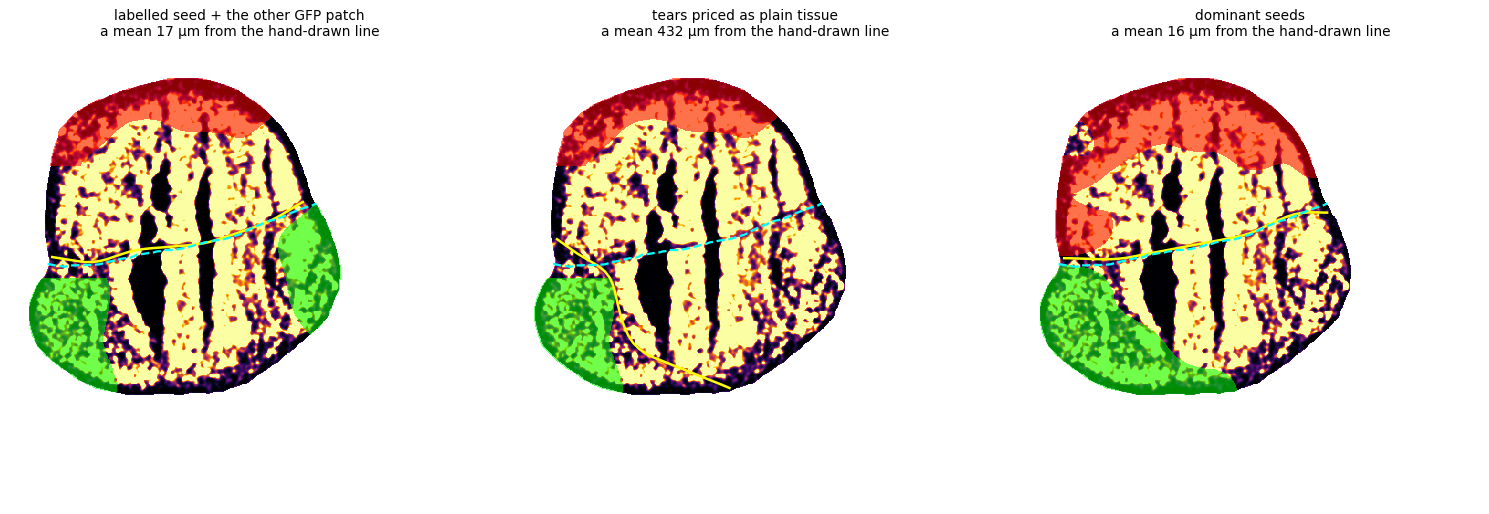

In [16]:
normal = jn._normalised(F.density, F.filled)
patches, count = ndimage.label((normal > 0.5) & F.filled)
second_patch = patches == (np.argsort(np.bincount(patches.ravel())[1:])[::-1][1] + 1)    # the second-largest GFP patch
wider = jn.split_tissue(F.filled, F.density, Fu, F_cost, seeds=(F_hot | second_patch, F_cold), bend_um=F_options.bend_um)
tried = [("labelled seed + the other GFP patch", jn.trace_interface(wider, Fu) * Fu, F_hot | second_patch, F_cold)]
for name, change in (("tears priced as plain tissue", {"tear_price": 1.0}), ("dominant seeds", {"seed_rule": "dominant"})):
    again = jn.find_junction(F_overview, jn.JunctionOptions(**{**F_options.__dict__, **change}))
    tried.append((name, again.line_um, *again.seeds))

fig, axes = plt.subplots(1, 3, figsize=(17, 5.6))
for ax, (name, line, a, b) in zip(axes, tried):
    show(ax, np.where(F.filled, F_cost, np.nan), f"{name}\na mean {off_by(line, F.filled, Fu, F_line):.0f} µm from the hand-drawn line",
         cmap="inferno", vmin=0, vmax=1)
    ax.contourf(a, [0.5, 1.5], colors=["lime"], alpha=0.55)
    ax.contourf(b, [0.5, 1.5], colors=["red"], alpha=0.55)
    ax.plot(line[:, 1] / Fu, line[:, 0] / Fu, color="yellow", lw=2)
    hand(ax, F_line, Fu)
plt.tight_layout()

### Why it fails

- **The seed is small and in a corner.** The labelled seed is only one of the two dense GFP patches of the labelled organoid, the lower-left one. The cut has to separate that corner from the other seed, and nothing more: it does not have to cross the whole section.
- **The tear is the cheapest road.** Long open tears run from the junction down to the lower edge. Empty of nuclei, they are the darkest, cheapest pixels of the section. The hand-drawn junction itself is faint here (mean price about 0.5, against 0.37 on the worked section). Going down a tear round the corner seed is far cheaper than crossing the section along the junction, and the saving outweighs the price of the one turn needed, so the bending price of step 5b does not stop it, as it did on the worked section.
- **The seed is the cause, the tear the road.** Give the labelled seed the other GFP patch too, and the line lands within about 20 µm of the hand-drawn one. Price the tears as plain tissue but keep the small seed, and the cut still wraps round the corner, just beside the tear. Dominant seeds also rescue this section; on the 30 annotated sections they were better held out but worse on the tuning set, so they are not the default ([junction_evaluation.ipynb](../validation/junction_evaluation.ipynb), *No clear junction*).
- **Why no flag.** A line down a tear looks like a confident one: very dark (seam price 0.23, the flag needs above 0.4), long, and the labelled half (20 % of the section) and the density contrast (1.9) are just inside their limits. *ok* only means no check fired.

**What to do.** Look at the QC picture of every section, not only those marked *check*: here a glance shows the band in the wrong place. Redraw it by hand (*Junction review* → *Redraw*); the hand-drawn band is then used in preference to the automatic one. The pixel-level version of this comparison is the last section of [junction_pixels.ipynb](junction_pixels.ipynb).